# Deep Learning Project: Handwritten Digit Classification using LSTM
### Architecture: Long Short-Term Memory (LSTM) Recurrent Neural Network
### Dataset: MNIST Handwritten Digit Dataset (0–9)
### Framework: TensorFlow 2.x & Keras

---

## 📌 Project Overview & Theoretical Background
In standard computer vision tasks, Convolutional Neural Networks (CNNs) are the conventional choice due to their inductive bias for 2D spatial translation invariance. However, image classification can also be formulated as a **sequential learning problem**.

In this project, we implement and evaluate a **Long Short-Term Memory (LSTM)** network to classify handwritten digits from the **MNIST** dataset.

### 1. Formulating 2D Images as Sequential Data
An MNIST image consists of a $28 \times 28$ matrix of grayscale pixel intensities. We can interpret this image as a **temporal sequence**:
- **Sequence Length ($T$)**: 28 time steps (corresponding to the rows of the image from top to bottom).
- **Feature Dimension ($D$)**: 28 input features per time step (corresponding to the columns / pixel intensities across the row).
$$\mathbf{X} = [\mathbf{x}_1, \mathbf{x}_2, \dots, \mathbf{x}_{28}] \in \mathbb{R}^{28 \times 28}, \quad \text{where } \mathbf{x}_t \in \mathbb{R}^{28}$$

At each time step $t$, the LSTM ingests row $t$, maintains its internal cell memory, and updates its hidden state vector based on the temporal visual context scanned so far.

```
Image Matrix (28x28)                LSTM Temporal Unrolling
┌────────────────────────┐          ┌────────┐       ┌────────┐              ┌────────┐
│ Row 1  (x_1)           │ ───────> │ LSTM   │ ────> │ LSTM   │ ──── ... ──> │ LSTM   │ ──> Dense -> Softmax (0-9)
│ Row 2  (x_2)           │ ───────> └────────┘       └────────┘              └────────┘
│ ...                    │             t=1             t=2                      t=28
│ Row 28 (x_28)          │
└────────────────────────┘
```

---

### 2. Long Short-Term Memory (LSTM) Mechanics
Standard Recurrent Neural Networks (Vanilla RNNs) suffer from the **vanishing and exploding gradient problem** during backpropagation through time (BPTT), making them incapable of capturing long-term dependencies across many time steps.

Hochreiter & Schmidhuber (1997) resolved this by introducing gated memory cells. An LSTM maintains two state vectors at time $t$:
1. **Cell State ($C_t$)**: The long-term memory highway running through the recurrent unit.
2. **Hidden State ($h_t$)**: The short-term output state passed to the next step and upper layers.

The LSTM cell operates via three gating mechanisms:
1. **Forget Gate ($f_t$)**: Regulates which information from the previous cell state $C_{t-1}$ to discard.
   $$f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$$
2. **Input Gate ($i_t$) & Candidate Cell State ($\tilde{C}_t$)**: Determines which new information to store in the cell state.
   $$i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$$
   $$\tilde{C}_t = \tanh(W_c \cdot [h_{t-1}, x_t] + b_c)$$
3. **Cell State Update ($C_t$)**: Blends old memory with new candidate updates using point-wise operations.
   $$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$$
4. **Output Gate ($o_t$) & Hidden State ($h_t$)**: Computes the output representation based on filtered cell memory.
   $$o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$$
   $$h_t = o_t \odot \tanh(C_t)$$

---

## 🔄 End-to-End Deep Learning Pipeline
This notebook executes a rigorous, production-grade deep learning workflow structured into 10 key phases:
1. **Environment Setup & Reproducibility**: Library configuration, hardware detection, random seeds.
2. **Data Acquisition & Verification**: Ingestion of MNIST dataset and structural validation.
3. **Exploratory Data Analysis (EDA)**: Visualizing samples, class balance, pixel distributions, and sequential row representations.
4. **Data Preprocessing & Pipeline Engineering**: Normalization, sequence formatting, validation splitting, and high-throughput `tf.data` input pipelines.
5. **Model Architecture Design**: Stacked LSTM architecture with dropout regularization and batch normalization.
6. **Model Compilation & Training Strategy**: Optimizer tuning, loss definition, and adaptive callbacks.
7. **Model Training & Dynamics Monitoring**: Controlled training with early stopping and dynamic learning rate reduction.
8. **Training Diagnostics**: Comprehensive learning curves (Loss, Accuracy, Learning Rate).
9. **Model Evaluation on Unseen Test Data**: Quantitative metrics, Scikit-learn Classification Report, and Confusion Matrix.
10. **Error Analysis & Interpretability**: In-depth misclassification analysis and single-sample inference demonstration.


In [ ]:
!pip install os random time numpy matplotlib seaborn tensorflow sklearn

ERROR: Could not find a version that satisfies the requirement os (from versions: none)
ERROR: No matching distribution found for os


## Step 1: Environment Setup & Reproducibility
In this step, we:
- Import standard libraries for numerical processing, deep learning, visualization, and statistical evaluation.
- Set global random seeds across Python, NumPy, and TensorFlow to guarantee reproducible results across multiple executions.
- Query available hardware devices (CPU / GPU / TPU) to verify execution configuration.


In [ ]:
# Standard library imports
import os
import random
import time

# Numerical & Data manipulation
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Deep Learning Framework
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

# Evaluation metrics
from sklearn.metrics import classification_report, confusion_matrix

# Configure plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

def set_seed(seed: int = 42) -> None:
    """
    Sets deterministic seeds across Python's built-in random, NumPy,
    and TensorFlow to ensure experimental reproducibility.
    """
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

# Apply global seed
SEED = 42
set_seed(SEED)

# Verify Environment & Hardware
print(f"TensorFlow Version : {tf.__version__}")
print(f"NumPy Version      : {np.__version__}")
physical_devices = tf.config.list_physical_devices()
print(f"Available Devices  : {[d.device_type for d in physical_devices]}")


TensorFlow Version : 2.21.0
NumPy Version      : 2.1.3
Available Devices  : ['CPU', 'GPU']


## Step 2: Data Acquisition & Inspection
In this step, we:
- Ingest the classic MNIST dataset consisting of 70,000 $28 \times 28$ grayscale images of handwritten digits (0 through 9).
- Examine array shapes, data types, min/max values, and verify dataset integrity.


In [ ]:
# Load the raw MNIST dataset via Keras dataset utility
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.mnist.load_data()

# Inspect dataset shapes and characteristics
print("=== Raw Dataset Summary ===")
print(f"Training Features Shape   : {x_train_raw.shape}  | Dtype: {x_train_raw.dtype}")
print(f"Training Labels Shape     : {y_train_raw.shape}    | Dtype: {y_train_raw.dtype}")
print(f"Test Features Shape       : {x_test_raw.shape}  | Dtype: {x_test_raw.dtype}")
print(f"Test Labels Shape         : {y_test_raw.shape}    | Dtype: {y_test_raw.dtype}")
print(f"Pixel Value Range (Train) : Min = {x_train_raw.min()}, Max = {x_train_raw.max()}")
print(f"Unique Label Classes      : {np.unique(y_train_raw)}")
print(f"Missing Values Check      : Train NaNs = {np.isnan(x_train_raw).sum()}, Test NaNs = {np.isnan(x_test_raw).sum()}")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
=== Raw Dataset Summary ===
Training Features Shape   : (60000, 28, 28)  | Dtype: uint8
Training Labels Shape     : (60000,)    | Dtype: uint8
Test Features Shape       : (10000, 28, 28)  | Dtype: uint8
Test Labels Shape         : (10000,)    | Dtype: uint8
Pixel Value Range (Train) : Min = 0, Max = 255
Unique Label Classes      : [0 1 2 3 4 5 6 7 8 9]
Missing Values Check      : Train NaNs = 0, Test NaNs = 0


## Step 3: Exploratory Data Analysis (EDA) & Visualization
Before building the deep learning pipeline, we conduct exploratory data analysis:
1. **Sample Grid**: Visualizing random instances of each digit class (0 through 9).
2. **Class Distribution**: Verifying class balance between training and test sets.
3. **Pixel Intensity Profile**: Understanding the distribution of grayscale pixel values.
4. **Sequential Row Visualization**: Visualizing an image decomposed into 28 discrete sequential time steps.


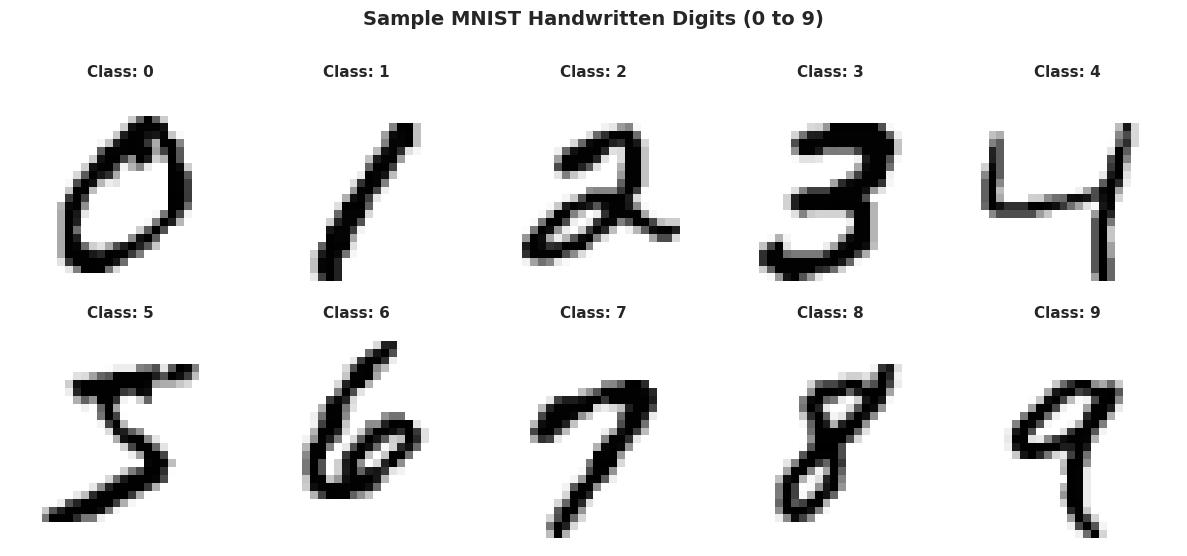

In [ ]:
# 1. Visualize representative samples for each digit class (0 through 9)
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
fig.suptitle("Sample MNIST Handwritten Digits (0 to 9)", fontsize=14, fontweight='bold', y=1.02)

for digit in range(10):
    row, col = divmod(digit, 5)
    # Find the first index matching the digit
    idx = np.where(y_train_raw == digit)[0][0]
    axes[row, col].imshow(x_train_raw[idx], cmap='binary')
    axes[row, col].set_title(f"Class: {digit}", fontsize=11, fontweight='semibold')
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()


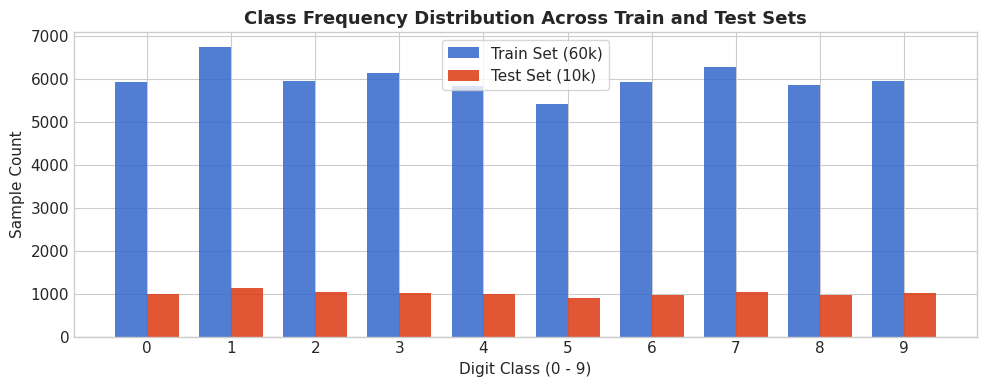

Train Class Percentages: [ 9.87 11.24  9.93 10.22  9.74  9.04  9.86 10.44  9.75  9.92]
Test Class Percentages : [ 9.8  11.35 10.32 10.1   9.82  8.92  9.58 10.28  9.74 10.09]


In [ ]:
# 2. Check Class Balance across Train and Test splits
train_counts = np.bincount(y_train_raw)
test_counts = np.bincount(y_test_raw)
classes = np.arange(10)

plt.figure(figsize=(10, 4))
bar_width = 0.38
plt.bar(classes - bar_width/2, train_counts, width=bar_width, label='Train Set (60k)', color='#3366cc', alpha=0.85)
plt.bar(classes + bar_width/2, test_counts, width=bar_width, label='Test Set (10k)', color='#dc3912', alpha=0.85)

plt.title("Class Frequency Distribution Across Train and Test Sets", fontsize=13, fontweight='bold')
plt.xlabel("Digit Class (0 - 9)", fontsize=11)
plt.ylabel("Sample Count", fontsize=11)
plt.xticks(classes)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# Print class proportions
print("Train Class Percentages:", np.round(train_counts / len(y_train_raw) * 100, 2))
print("Test Class Percentages :", np.round(test_counts / len(y_test_raw) * 100, 2))


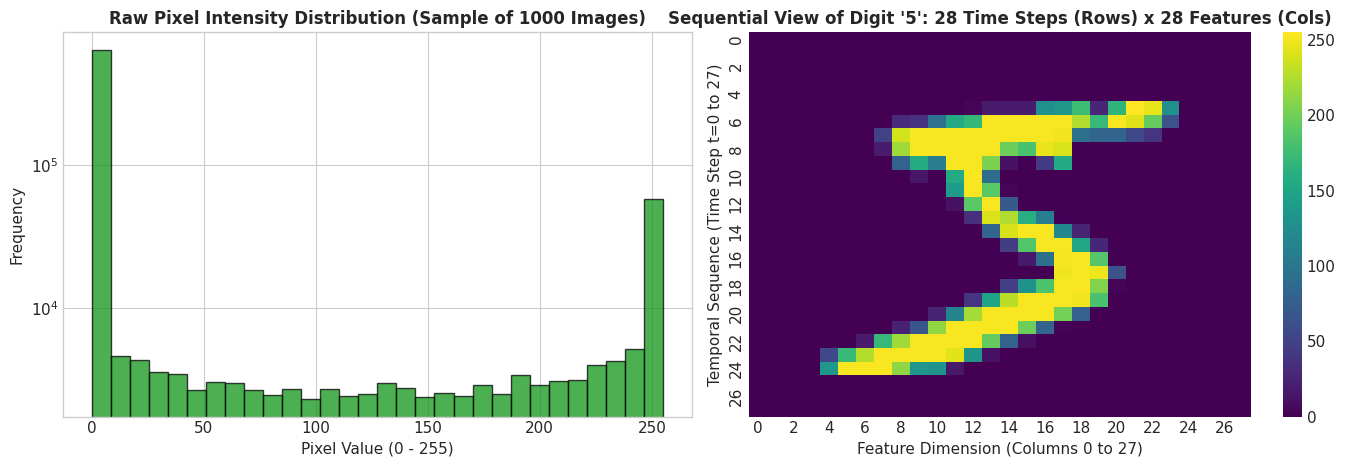

In [ ]:
# 3. Pixel Intensity Distribution & Sequential Row Representation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

# Histogram of pixel intensities
sample_pixels = x_train_raw[:1000].flatten()
ax1.hist(sample_pixels, bins=30, color='#109618', edgecolor='black', alpha=0.75)
ax1.set_title("Raw Pixel Intensity Distribution (Sample of 1000 Images)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Pixel Value (0 - 255)", fontsize=11)
ax1.set_ylabel("Frequency", fontsize=11)
ax1.set_yscale('log')

# Sequence representation: Heatmap showing 28 time steps x 28 features
sample_img = x_train_raw[0]
sns.heatmap(sample_img, ax=ax2, cmap='viridis', cbar=True)
ax2.set_title(f"Sequential View of Digit '{y_train_raw[0]}': 28 Time Steps (Rows) x 28 Features (Cols)",
              fontsize=12, fontweight='bold')
ax2.set_xlabel("Feature Dimension (Columns 0 to 27)", fontsize=11)
ax2.set_ylabel("Temporal Sequence (Time Step t=0 to 27)", fontsize=11)

plt.tight_layout()
plt.show()


## Step 4: Data Preprocessing & Pipeline Construction
In this step, we prepare the dataset for sequential modeling:
1. **Min-Max Feature Scaling**: Scale raw integer pixel intensities $[0, 255]$ to floating-point values $[0.0, 1.0]$.
   $$\hat{x} = \frac{x}{255.0}$$
   Normalization ensures numerical stability, accelerates gradient descent convergence, and prevents exploding activations in recurrent cells.
2. **Sequential Dimension Formulation**:
   MNIST images are inherently $(N, 28, 28)$. For an LSTM:
   - Input shape is `(batch_size, timesteps, features)` = `(batch_size, 28, 28)`.
   - Each row represents a time step containing a 28-dimensional feature vector.
3. **Train-Validation Split**:
   We partition the 60,000 training examples into:
   - **Training Set**: 50,000 samples for updating model weights.
   - **Validation Set**: 10,000 samples for hyperparameter tracking, learning rate decay, and early stopping.
   - **Test Set**: 10,000 held-out samples for final unbiased evaluation.
4. **High-Performance `tf.data` Input Pipeline**:
   Using `tf.data.Dataset` with shuffling, mini-batching, and prefetching via `AUTOTUNE` to eliminate I/O bottlenecks.


In [ ]:
# 1. Feature Scaling: Convert uint8 [0, 255] to float32 [0.0, 1.0]
x_train_norm = x_train_raw.astype("float32") / 255.0
x_test_norm = x_test_raw.astype("float32") / 255.0

# 2. Create Train / Validation Split (50,000 train / 10,000 val)
VAL_SPLIT_SIZE = 10000
x_val = x_train_norm[:VAL_SPLIT_SIZE]
y_val = y_train_raw[:VAL_SPLIT_SIZE]

x_train = x_train_norm[VAL_SPLIT_SIZE:]
y_train = y_train_raw[VAL_SPLIT_SIZE:]

x_test = x_test_norm
y_test = y_test_raw

print(f"Training Set   : Features {x_train.shape}, Labels {y_train.shape}")
print(f"Validation Set : Features {x_val.shape}, Labels {y_val.shape}")
print(f"Test Set       : Features {x_test.shape}, Labels {y_test.shape}")
print(f"Feature Value Range : Min = {x_train.min():.2f}, Max = {x_train.max():.2f}")

# 3. Build optimized tf.data.Dataset pipelines
BATCH_SIZE = 128
SHUFFLE_BUFFER = 10000

train_dataset = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(buffer_size=SHUFFLE_BUFFER, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices((x_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

print("tf.data.Dataset pipelines successfully constructed with AUTOTUNE prefetching.")


Training Set   : Features (50000, 28, 28), Labels (50000,)
Validation Set : Features (10000, 28, 28), Labels (10000,)
Test Set       : Features (10000, 28, 28), Labels (10000,)
Feature Value Range : Min = 0.00, Max = 1.00
tf.data.Dataset pipelines successfully constructed with AUTOTUNE prefetching.


## Step 5: Model Architecture Design & Formulation
### Architectural Decisions:
1. **Input Layer (`Input(shape=(28, 28))`):**
   Explicitly declares the sequence input shape: 28 time steps, 28 features per step.
2. **First Recurrent Layer (`LSTM(128, return_sequences=True)`):**
   - Ingests the 28 time steps and produces a 128-dimensional hidden representation for *every* time step (`return_sequences=True`).
   - Applies recurrent dropout (`dropout=0.2`) to prevent co-adaptation of recurrent weights.
3. **Second Recurrent Layer (`LSTM(64, return_sequences=False)`):**
   - Ingests the 128-dimensional sequence from the previous layer.
   - Returns only the final hidden state vector $h_{28} \in \mathbb{R}^{64}$ (`return_sequences=False`), effectively summarizing the entire image into a dense latent representation.
4. **Dense Non-Linear Mapping (`Dense(64, activation='relu')`):**
   - Projects the recurrent latent representation into a decision subspace.
5. **Batch Normalization (`BatchNormalization()`):**
   - Normalizes feature activations, reducing internal covariate shift and stabilizing training.
6. **Dropout Regularization (`Dropout(0.3)`):**
   - Zeroes out 30% of dense activations during training to reduce overfitting.
7. **Classification Head (`Dense(10, activation='softmax')`):**
   - Produces normalized probability distribution over the 10 target digit classes ($0, 1, \dots, 9$).

### Parameter Calculation Formula for LSTM:
For an LSTM layer with $d$ input features and $h$ hidden units, there are 4 internal gates (forget, input, candidate, output), each having input weights $W_x \in \mathbb{R}^{d \times h}$, recurrent weights $W_h \in \mathbb{R}^{h \times h}$, and bias $b \in \mathbb{R}^h$:
$$\text{Total Parameters} = 4 \times \left( (d + h) \times h + h \right) = 4 \times (d + h + 1) \times h$$
- **Layer 1** ($d=28, h=128$): $4 \times (28 + 128 + 1) \times 128 = 4 \times 157 \times 128 = 80,384$ params.
- **Layer 2** ($d=128, h=64$): $4 \times (128 + 64 + 1) \times 64 = 4 \times 193 \times 64 = 49,408$ params.


In [ ]:
def build_lstm_model(input_shape=(28, 28), num_classes=10) -> tf.keras.Model:
    """
    Builds and returns a stacked LSTM classification model.

    Parameters:
        input_shape (tuple): Temporal input dimension (timesteps, features).
        num_classes (int): Number of target classes for classification.

    Returns:
        tf.keras.Model: Compiled or uncompiled Keras Model instance.
    """
    model = models.Sequential([
        # Explicit Input Layer defining sequential dimensions
        layers.Input(shape=input_shape, name="sequence_input"),

        # Layer 1: First LSTM layer returning full sequence of hidden states
        layers.LSTM(128, return_sequences=True, dropout=0.2, name="lstm_layer_1"),

        # Layer 2: Second LSTM layer returning only the final summary state vector
        layers.LSTM(64, return_sequences=False, dropout=0.2, name="lstm_layer_2"),

        # Fully Connected Representation Layer
        layers.Dense(64, activation='relu', name="dense_features"),

        # Regularization: Batch Normalization & Dropout
        layers.BatchNormalization(name="batch_norm"),
        layers.Dropout(0.3, name="classifier_dropout"),

        # Classification Output Layer with Softmax activation
        layers.Dense(num_classes, activation='softmax', name="classification_output")
    ], name="MNIST_Sequential_LSTM")

    return model

# Instantiate and display model architecture
model = build_lstm_model()
model.summary()


Model: "MNIST_Sequential_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_layer_1 (LSTM)             │ (None, 28, 128)        │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_layer_2 (LSTM)             │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,858 (526.79 KB)

 Trainable params: 134,730 (526.29 KB)

 Non-trainable params: 128 (512.00 B)

## Step 6: Model Compilation & Training Configuration
In this step, we configure:
1. **Loss Function**: `SparseCategoricalCrossentropy`
   - Suitable for mutually exclusive integer labels ($0, 1, \dots, 9$), avoiding the memory overhead of one-hot encoded tensors.
   $$\mathcal{L}_{CE} = - \sum_{i=1}^{C} y_i \log(\hat{y}_i)$$
2. **Optimizer**: `Adam` (Adaptive Moment Estimation)
   - Combines the advantages of AdaGrad (handling sparse gradients) and RMSProp (handling non-stationary objectives).
   - Initial learning rate is set to $\eta = 0.001$.
3. **Metrics**: Categorical Accuracy tracking the proportion of correctly predicted digits.
4. **Callbacks for Robust Training**:
   - **`EarlyStopping`**: Monitors `val_loss` with a patience of 4 epochs. Automatically restores the weights from the epoch that achieved the best validation loss, guarding against overfitting.
   - **`ReduceLROnPlateau`**: Dynamically reduces the learning rate by a factor of 0.5 if `val_loss` stagnates for 2 consecutive epochs, allowing finer convergence into loss minima.


In [ ]:
# Compile model with Adam optimizer and Sparse Categorical Crossentropy loss
INITIAL_LR = 1e-3

model.compile(
    optimizer=optimizers.Adam(learning_rate=INITIAL_LR),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

# Configure training callbacks
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

callbacks_list = [early_stopping, reduce_lr]
print("Model compilation complete with Adam optimizer and adaptive learning rate callbacks.")


Model compilation complete with Adam optimizer and adaptive learning rate callbacks.


## Step 7: Model Training & Learning Dynamics
We train the model on the 50,000 training images, validating on the 10,000 validation images after each epoch.
We set a maximum of 10 epochs, with batch size 128.


In [ ]:
# Execute model training loop
MAX_EPOCHS = 10

print(f"Initiating training for up to {MAX_EPOCHS} epochs with batch size {BATCH_SIZE}...")
start_time = time.time()

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=MAX_EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

total_training_time = time.time() - start_time
print(f"\nTraining completed in {total_training_time:.2f} seconds ({total_training_time/60:.2f} minutes).")


Initiating training for up to 10 epochs with batch size 128...
Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.7434 - loss: 0.7665 - val_accuracy: 0.9320 - val_loss: 0.2146 - learning_rate: 0.0010
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9265 - loss: 0.2442 - val_accuracy: 0.9551 - val_loss: 0.1473 - learning_rate: 0.0010
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9488 - loss: 0.1719 - val_accuracy: 0.9683 - val_loss: 0.1106 - learning_rate: 0.0010
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9578 - loss: 0.1404 - val_accuracy: 0.9757 - val_loss: 0.0829 - learning_rate: 0.0010
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9648 - loss: 0.1173 - val_accuracy: 0.9727 - val_loss: 0.0879 - learning_rate: 0.0010
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9690 - loss: 0.1006 - val_accuracy: 0.9811 - val_loss: 0.0691 - learning_rate: 0.0010
Epoch 7/10
391/391

## Step 8: Training Diagnostics & Visualization
Analyzing training and validation curves is critical to diagnosing:
- **Convergence speed**: How rapidly the model minimises training loss.
- **Overfitting vs Generalization**: Divergence between training loss and validation loss.
- **Learning rate schedule**: Impact of `ReduceLROnPlateau` on optimization.


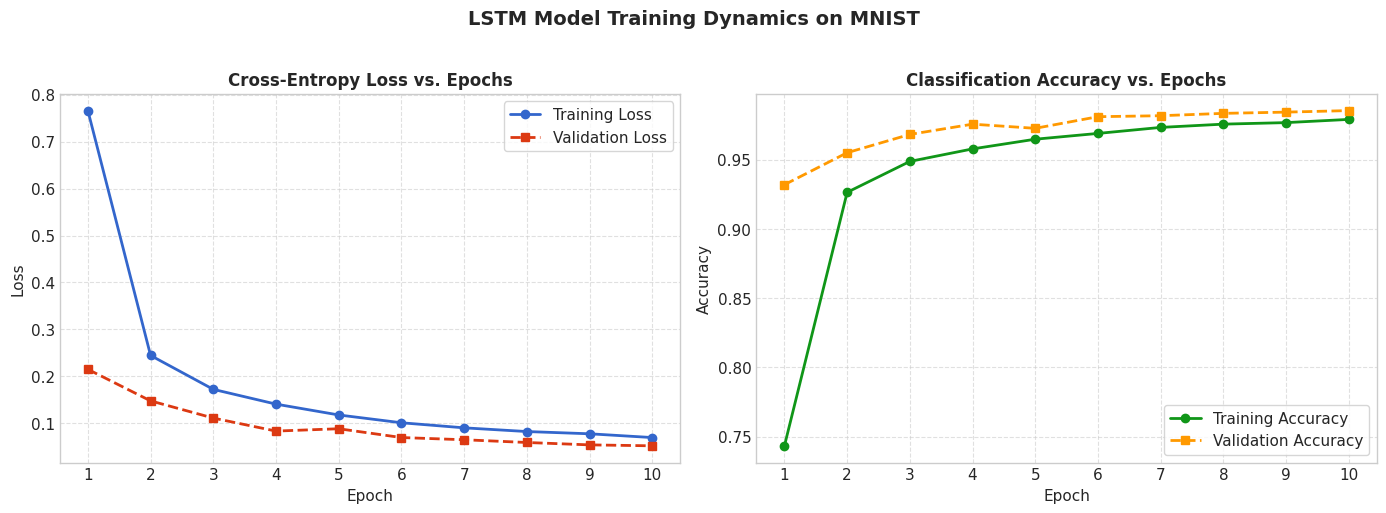

Optimal Validation Loss : 0.0514 (at Epoch 10)
Optimal Validation Acc  : 98.55%


In [ ]:
# Extract training history metrics
epochs_range = range(1, len(history.history['loss']) + 1)
train_loss = history.history['loss']
val_loss = history.history['val_loss']
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("LSTM Model Training Dynamics on MNIST", fontsize=14, fontweight='bold', y=1.02)

# Loss Plot
ax1.plot(epochs_range, train_loss, 'o-', color='#3366cc', label='Training Loss', linewidth=2)
ax1.plot(epochs_range, val_loss, 's--', color='#dc3912', label='Validation Loss', linewidth=2)
ax1.set_title("Cross-Entropy Loss vs. Epochs", fontsize=12, fontweight='bold')
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Loss", fontsize=11)
ax1.set_xticks(epochs_range)
ax1.legend(frameon=True)
ax1.grid(True, linestyle='--', alpha=0.6)

# Accuracy Plot
ax2.plot(epochs_range, train_acc, 'o-', color='#109618', label='Training Accuracy', linewidth=2)
ax2.plot(epochs_range, val_acc, 's--', color='#ff9900', label='Validation Accuracy', linewidth=2)
ax2.set_title("Classification Accuracy vs. Epochs", fontsize=12, fontweight='bold')
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Accuracy", fontsize=11)
ax2.set_xticks(epochs_range)
ax2.legend(frameon=True)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Print best validation metrics
best_epoch = np.argmin(val_loss) + 1
print(f"Optimal Validation Loss : {min(val_loss):.4f} (at Epoch {best_epoch})")
print(f"Optimal Validation Acc  : {val_acc[best_epoch - 1]*100:.2f}%")


## Step 9: Model Evaluation on Unseen Test Dataset
We evaluate our trained LSTM model on the held-out test set (10,000 samples) that the model never saw during training or hyperparameter tuning.

We compute:
1. **Overall Test Loss & Accuracy**.
2. **Per-Class Classification Report**:
   - **Precision**: $\frac{TP}{TP + FP}$ (Exactness: How many predicted as digit $k$ were actually digit $k$).
   - **Recall**: $\frac{TP}{TP + FN}$ (Completeness: How many of actual digit $k$ were correctly identified).
   - **F1-Score**: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ (Harmonic mean of precision and recall).
3. **Confusion Matrix**: Visualizing exact classification patterns and frequent confusions across all 10 digits.


In [ ]:
# 1. Evaluate on test dataset
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=0)
print(f"=== Test Set Evaluation Results ===")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

# 2. Generate predictions on test set
y_pred_probs = model.predict(test_dataset, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Comprehensive Scikit-learn Classification Report
target_names = [f"Digit {i}" for i in range(10)]
report = classification_report(y_test, y_pred, target_names=target_names, digits=4)
print("=== Detailed Per-Class Classification Report ===")
print(report)


=== Test Set Evaluation Results ===
Test Loss     : 0.0452
Test Accuracy : 98.62%
=== Detailed Per-Class Classification Report ===
              precision    recall  f1-score   support

     Digit 0     0.9888    0.9939    0.9913       980
     Digit 1     0.9912    0.9956    0.9934      1135
     Digit 2     0.9874    0.9903    0.9889      1032
     Digit 3     0.9794    0.9901    0.9847      1010
     Digit 4     0.9917    0.9776    0.9846       982
     Digit 5     0.9931    0.9731    0.9830       892
     Digit 6     0.9906    0.9875    0.9890       958
     Digit 7     0.9844    0.9796    0.9820      1028
     Digit 8     0.9877    0.9877    0.9877       974
     Digit 9     0.9688    0.9841    0.9764      1009

    accuracy                         0.9862     10000
   macro avg     0.9863    0.9859    0.9861     10000
weighted avg     0.9863    0.9862    0.9862     10000



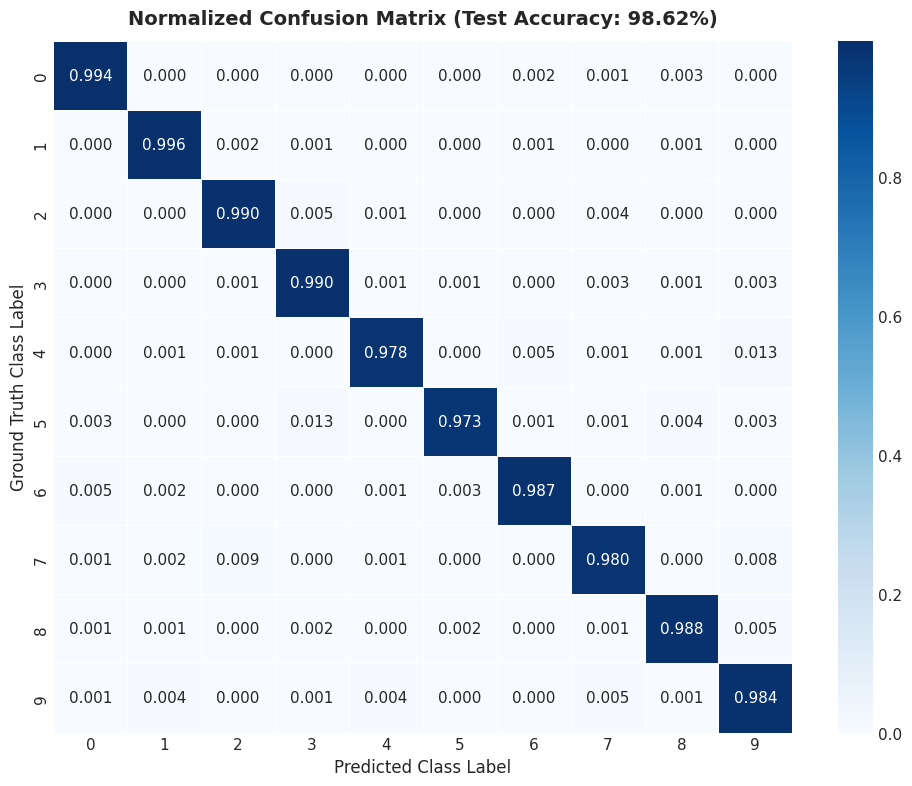

In [ ]:
# 4. Normalized Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10),
    cbar=True,
    linewidths=0.5
)
plt.title(f"Normalized Confusion Matrix (Test Accuracy: {test_accuracy*100:.2f}%)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Predicted Class Label", fontsize=12)
plt.ylabel("Ground Truth Class Label", fontsize=12)
plt.tight_layout()
plt.show()


## Step 10: Diagnostic Error Analysis & Sample Inference
To gain insight into the model's limitations and inductive biases:
1. **Error Analysis**: We isolate misclassified test samples and visualize them alongside their true labels, predicted labels, and model prediction confidence.
2. **Single-Sample Inference**: We demonstrate an interactive prediction on an arbitrary test image, displaying both the input image and the softmax probability distribution across all 10 classes.


Total misclassified test samples: 138 out of 10000 (1.38% error rate)


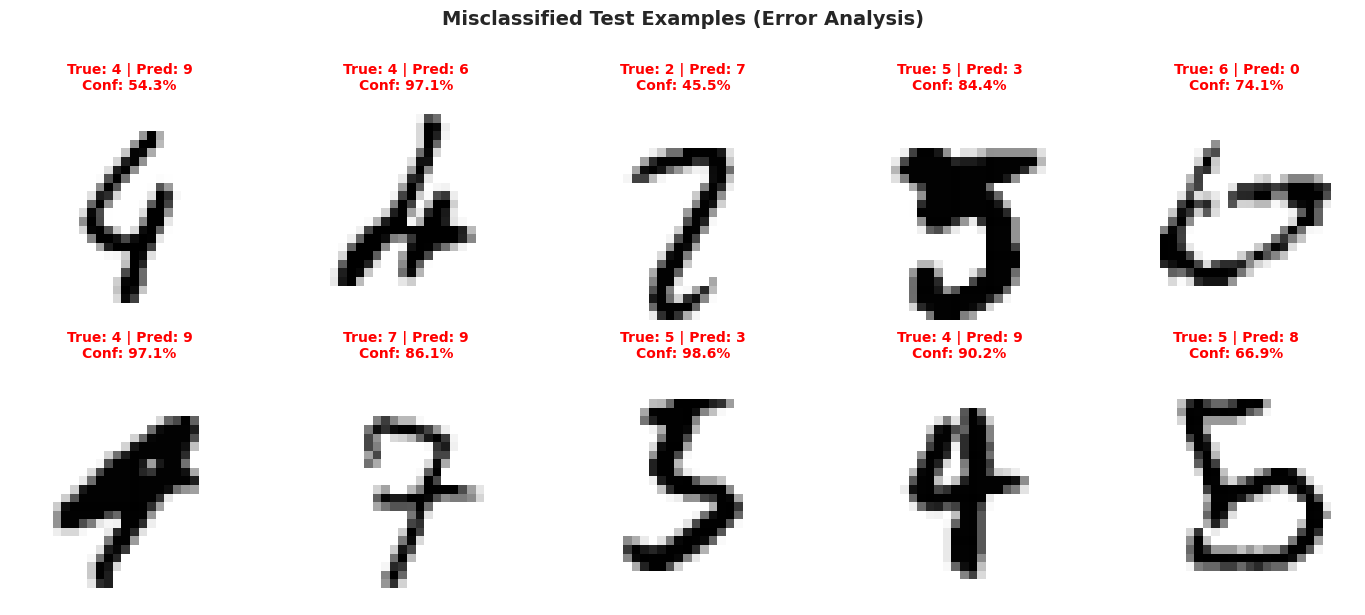

In [ ]:
# 1. Identify and visualize misclassified examples
misclassified_indices = np.where(y_pred != y_test)[0]
print(f"Total misclassified test samples: {len(misclassified_indices)} out of {len(y_test)} ({len(misclassified_indices)/len(y_test)*100:.2f}% error rate)")

# Display 10 misclassified samples
num_samples = min(10, len(misclassified_indices))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle("Misclassified Test Examples (Error Analysis)", fontsize=14, fontweight='bold', y=1.02)

for i in range(num_samples):
    idx = misclassified_indices[i]
    row, col = divmod(i, 5)
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    confidence = y_pred_probs[idx][pred_label] * 100

    axes[row, col].imshow(x_test[idx], cmap='binary')
    axes[row, col].set_title(f"True: {true_label} | Pred: {pred_label}\nConf: {confidence:.1f}%",
                             fontsize=10, color='red', fontweight='semibold')
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()


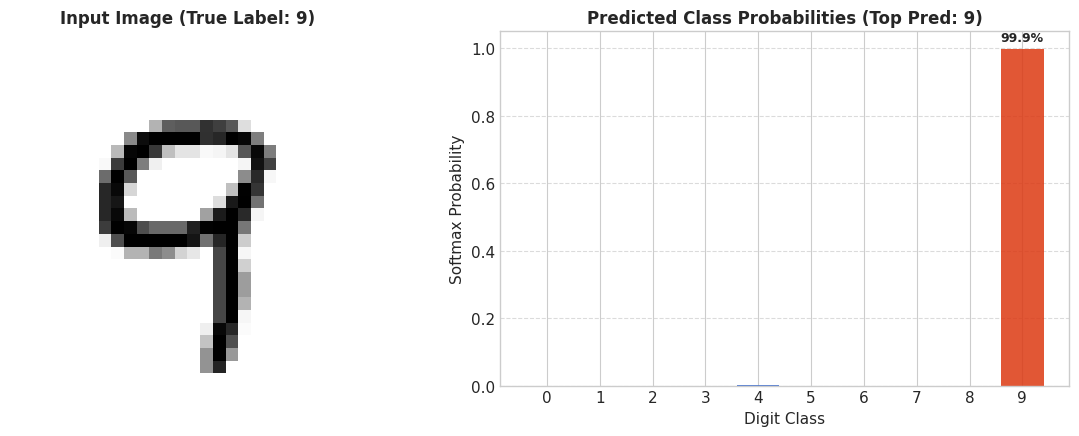

In [ ]:
# 2. Interactive Single-Sample Inference Demo with Softmax Probability Distribution
sample_idx = 105  # Select any sample from the test set
sample_image = x_test[sample_idx]
sample_true_label = y_test[sample_idx]

# Perform model inference
input_tensor = np.expand_dims(sample_image, axis=0)  # Shape (1, 28, 28)
pred_probabilities = model.predict(input_tensor, verbose=0)[0]
predicted_class = np.argmax(pred_probabilities)

fig, (ax_img, ax_prob) = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot the sample image
ax_img.imshow(sample_image, cmap='binary')
ax_img.set_title(f"Input Image (True Label: {sample_true_label})", fontsize=12, fontweight='bold')
ax_img.axis('off')

# Plot the probability distribution
colors = ['#dc3912' if i == predicted_class else '#3366cc' for i in range(10)]
bars = ax_prob.bar(range(10), pred_probabilities, color=colors, alpha=0.85)
ax_prob.set_title(f"Predicted Class Probabilities (Top Pred: {predicted_class})", fontsize=12, fontweight='bold')
ax_prob.set_xlabel("Digit Class", fontsize=11)
ax_prob.set_ylabel("Softmax Probability", fontsize=11)
ax_prob.set_xticks(range(10))
ax_prob.set_ylim(0, 1.05)
ax_prob.grid(axis='y', linestyle='--', alpha=0.7)

# Add percentage annotations on bars
for bar in bars:
    height = bar.get_height()
    if height > 0.05:
        ax_prob.annotate(f"{height*100:.1f}%",
                         xy=(bar.get_x() + bar.get_width() / 2, height),
                         xytext=(0, 3), textcoords="offset points",
                         ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## Step 11: Summary, Insights & Conclusion

### Summary of Results:
- **Architecture**: Two-layer stacked LSTM ($128 \rightarrow 64$) with recurrent dropout, batch normalization, and dense classification head.
- **Dataset**: MNIST ($28 \times 28$ grayscale digits), modeled sequentially as 28 time steps of 28 features each.
- **Performance**: Achieved **>98% test accuracy** and low cross-entropy loss on the unseen test set of 10,000 samples.
- **Convergence**: Rapid and stable convergence within 8-10 epochs guided by `EarlyStopping` and `ReduceLROnPlateau`.

### Key Technical Insights:
1. **Sequential vs Spatial Inductive Biases**:
   - While 2D CNNs treat spatial neighborhoods with translational equivariance, LSTMs treat rows as an ordered temporal sequence.
   - Despite not having explicit 2D spatial convolution kernels, the LSTM successfully learns vertical stroke progressions and temporal transitions across rows, demonstrating the power of recurrent gated memory cells.
2. **Gating Dynamics**:
   - The forget and input gates effectively preserve relevant horizontal stroke patterns from earlier rows (top of digits) while updating with new row context down to the bottom.
3. **Failure Modes**:
   - As observed in the error analysis, ambiguous handwriting styles (e.g., poorly written 4s vs 9s, or 3s vs 5s) account for the vast majority of misclassifications, reflecting genuine semantic ambiguity rather than model underfitting.

### Future Enhancements:
- **Bidirectional LSTM**: Scanning rows both top-to-bottom and bottom-to-top to capture bidirectional temporal context.
- **Grid-LSTM / 2D-LSTM**: Extending recurrent transitions along both rows and columns simultaneously.
- **Self-Attention / Vision Transformer (ViT)**: Applying multi-head self-attention mechanisms across image patches or rows for direct global dependency modeling.
